In [1]:
# Importação de bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.cm as cm
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('/kaggle/input/tp2-data-exploration/bank-full.csv', sep=';') 
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [4]:
# Remover espaços em branco das colunas
df.columns = df.columns.str.strip()

# Verificar valores "unknown" e convertê-los para NaN
for col in df.columns:
    if df[col].dtype == 'object':
        print(f"{col}: {df[col].value_counts().get('unknown', 0)} 'unknown' encontrados")
df.replace('unknown', np.nan, inplace=True)

# Preencher valores ausentes
for col in df.columns:
    if df[col].dtype == 'object':
        df[col].fillna(df[col].mode()[0], inplace=True)
    else:
        df[col].fillna(df[col].mean(), inplace=True)

# Atualizar dataset limpo
df_clean = df.copy()
print("Dimensão final do dataset limpo:", df_clean.shape)

job: 288 'unknown' encontrados
marital: 0 'unknown' encontrados
education: 1857 'unknown' encontrados
default: 0 'unknown' encontrados
housing: 0 'unknown' encontrados
loan: 0 'unknown' encontrados
contact: 13020 'unknown' encontrados
month: 0 'unknown' encontrados
poutcome: 36959 'unknown' encontrados
y: 0 'unknown' encontrados
Dimensão final do dataset limpo: (45211, 17)


In [5]:
df_clean['y_num'] = df_clean['y'].map({'no': 0, 'yes': 1})

# Lista de atributos numéricos
atributos_numericos = ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']

# Features e target
X = df_clean[atributos_numericos]
y_classificacao = df_clean['y_num'] 
y_regressao = df_clean['balance']  

In [6]:
# Usar as mesmas features contínuas
X = df_clean[atributos_numericos]
y = df_clean['y_num']

# Divisão dos dados
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

Árvore de Decisão
Acurácia: 0.89
Relatório:
               precision    recall  f1-score   support

           0       0.90      0.98      0.94     11966
           1       0.57      0.19      0.28      1598

    accuracy                           0.89     13564
   macro avg       0.74      0.58      0.61     13564
weighted avg       0.86      0.89      0.86     13564



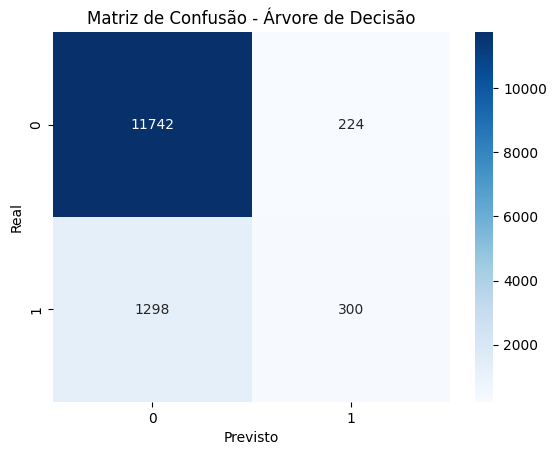

In [7]:
# Modelo de árvore de decisão
tree_clf = DecisionTreeClassifier(max_depth=4, random_state=42)
tree_clf.fit(X_train, y_train)

# Previsões
y_pred_tree = tree_clf.predict(X_test)

# Avaliação
print("Árvore de Decisão")
print(f"Acurácia: {accuracy_score(y_test, y_pred_tree):.2f}")
print("Relatório:\n", classification_report(y_test, y_pred_tree))

# Matriz de confusão
sns.heatmap(confusion_matrix(y_test, y_pred_tree), annot=True, fmt='d', cmap='Blues')
plt.title("Matriz de Confusão - Árvore de Decisão")
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.show()

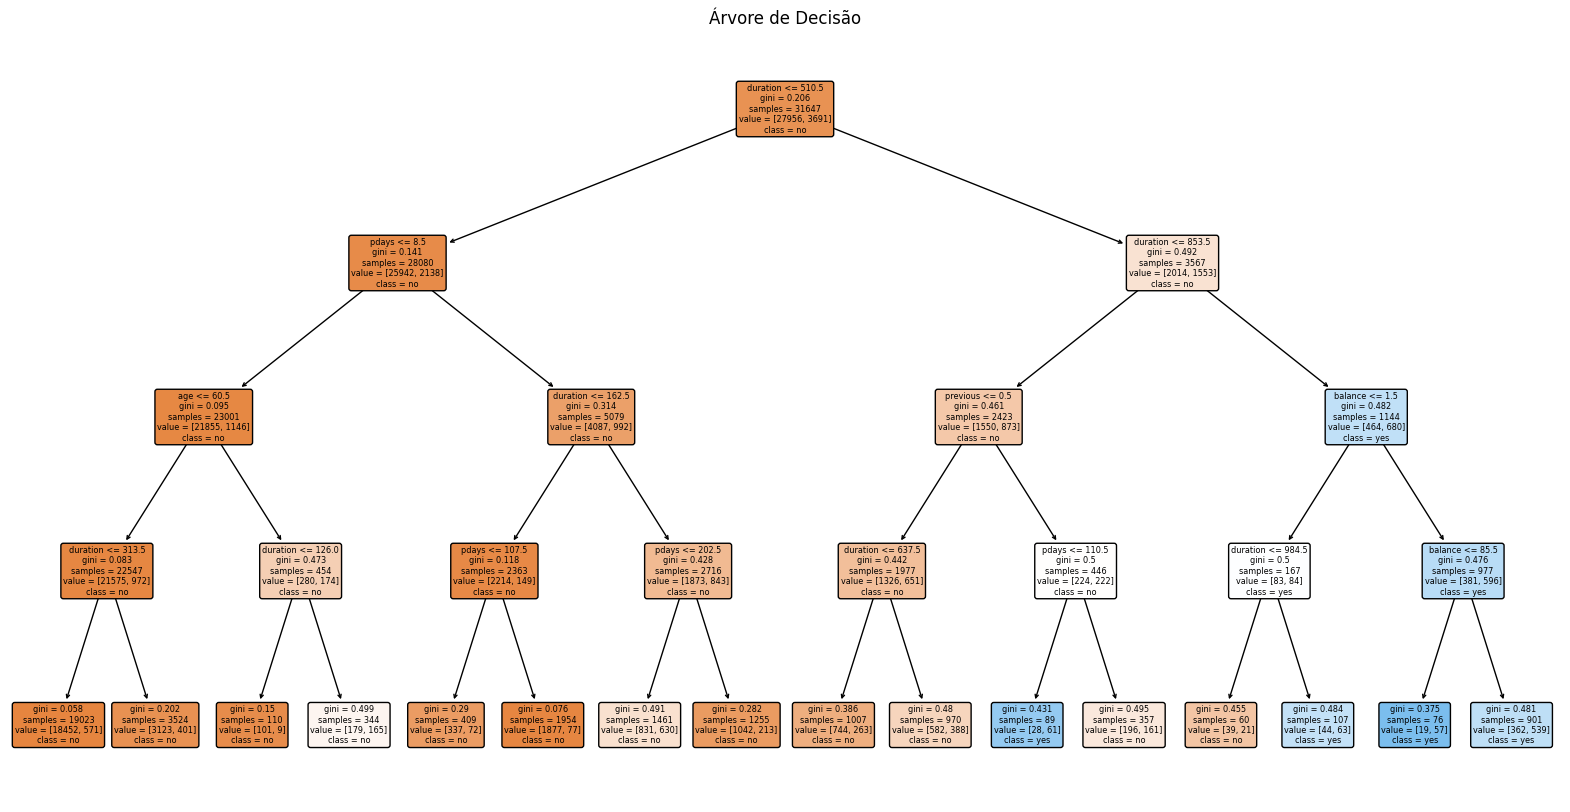

In [8]:
# Visualização da Decision tree
plt.figure(figsize=(20,10))
plot_tree(tree_clf, feature_names=X.columns, class_names=['no', 'yes'], filled=True, rounded=True)
plt.title("Árvore de Decisão")
plt.show()

Random Forest
Acurácia: 0.89
Relatório:
               precision    recall  f1-score   support

           0       0.91      0.96      0.94     11966
           1       0.55      0.32      0.41      1598

    accuracy                           0.89     13564
   macro avg       0.73      0.64      0.67     13564
weighted avg       0.87      0.89      0.88     13564



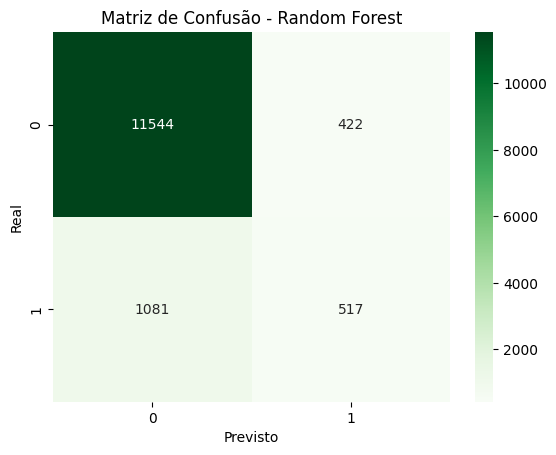

In [9]:
# Modelo Random Forest
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf.fit(X_train, y_train)

# Previsões
y_pred_rf = rf_clf.predict(X_test)

# Avaliação
print("Random Forest")
print(f"Acurácia: {accuracy_score(y_test, y_pred_rf):.2f}")
print("Relatório:\n", classification_report(y_test, y_pred_rf))

# Matriz de confusão
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Greens')
plt.title("Matriz de Confusão - Random Forest")
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.show()

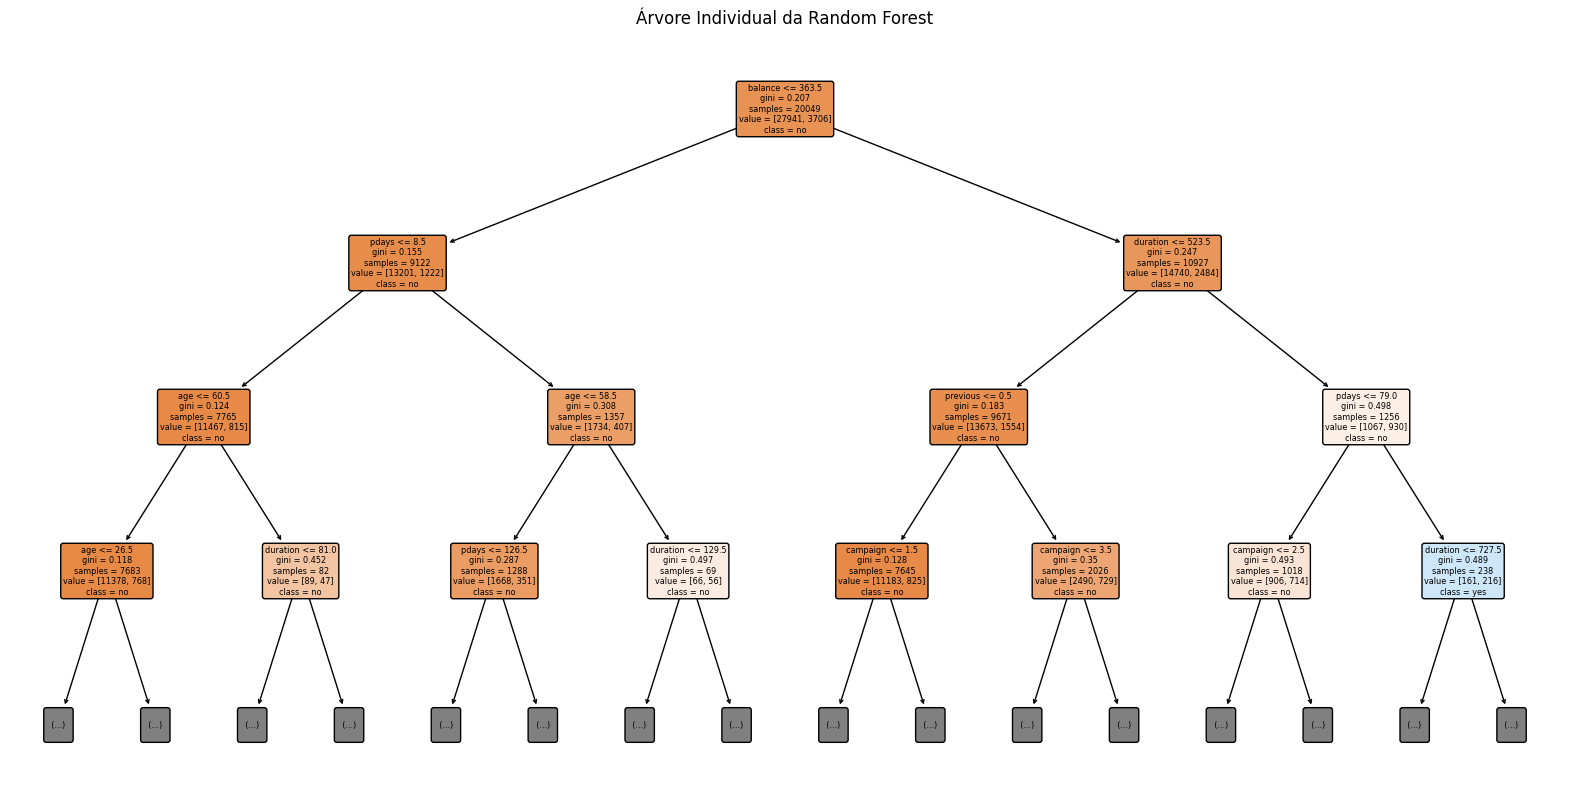

In [10]:
# Visualização de Random Forest
plt.figure(figsize=(20, 10))
plot_tree(rf_clf.estimators_[0], 
          feature_names=atributos_numericos, 
          class_names=['no', 'yes'], 
          filled=True, 
          rounded=True, 
          max_depth=3)  
plt.title("Árvore Individual da Random Forest")
plt.show()

In [11]:
novo_registo = pd.DataFrame([{
    'age': 40,
    'balance': 1200,
    'duration': 200,
    'campaign': 2,
    'pdays': 999,
    'previous': 0
}])

# Previsão com Árvore
pred_tree = tree_clf.predict(novo_registo)[0]

# Previsão com Random Forest
pred_rf = rf_clf.predict(novo_registo)[0]

print(f"Previsão (Árvore de Decisão): {'yes' if pred_tree == 1 else 'no'}")
print(f"Previsão (Random Forest): {'yes' if pred_rf == 1 else 'no'}")

Previsão (Árvore de Decisão): no
Previsão (Random Forest): no
